In [1]:
import re, random
from collections import Counter, defaultdict
from nltk import ngrams
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
corpus = """Natural language processing is a field of artificial intelligence.
Natural language processing helps computers understand human language.
Language models predict the next word in a sentence.
Natural language processing is used in chatbots and search engines.
Computers understand human language using language models."""
# To use your own file:  corpus = open("mytext.txt").read()

words = re.findall(r"[a-z']+", corpus.lower())
print("Total tokens:", len(words), "| Unique:", len(set(words)))

Total tokens: 43 | Unique: 26


In [3]:
uni = Counter(words)
bi  = Counter(ngrams(words, 2))
tri = Counter(ngrams(words, 3))

print("Top 5 unigrams:", uni.most_common(5))
print("Top 5 bigrams :", bi.most_common(5))
print("Top 5 trigrams:", tri.most_common(5))

Top 5 unigrams: [('language', 7), ('natural', 3), ('processing', 3), ('is', 2), ('a', 2)]
Top 5 bigrams : [(('natural', 'language'), 3), (('language', 'processing'), 3), (('processing', 'is'), 2), (('computers', 'understand'), 2), (('understand', 'human'), 2)]
Top 5 trigrams: [(('natural', 'language', 'processing'), 3), (('language', 'processing', 'is'), 2), (('computers', 'understand', 'human'), 2), (('understand', 'human', 'language'), 2), (('processing', 'is', 'a'), 1)]


In [4]:
def bigram_prob(w1, w2):
    return bi[(w1, w2)] / uni[w1] if uni[w1] else 0

def trigram_prob(w1, w2, w3):
    return tri[(w1, w2, w3)] / bi[(w1, w2)] if bi[(w1, w2)] else 0

print("P(language | natural)         =", bigram_prob("natural", "language"))
print("P(processing | natural language) =", trigram_prob("natural", "language", "processing"))

rows = [(" ".join(g), c, round(c/uni[g[0]], 3)) for g, c in bi.most_common(8)]
display(pd.DataFrame(rows, columns=["bigram", "count", "P(w2|w1)"]))

P(language | natural)         = 1.0
P(processing | natural language) = 1.0


,bigram,count,P(w2|w1)
0,natural language,3,1.000
1,language processing,3,0.429
2,processing is,2,0.667
3,computers understand,2,1.000
4,understand human,2,1.000
5,human language,2,1.000
6,language models,2,0.286
7,is a,1,0.500


In [5]:
def build_model(n):
    model = defaultdict(list)
    for g in ngrams(words, n):
        model[g[:-1]].append(g[-1])
    return model

def generate(n, seed, length=12):
    model = build_model(n)
    out = list(seed)
    for _ in range(length):
        nxt = model.get(tuple(out[-(n-1):]))
        if not nxt: break
        out.append(random.choice(nxt))
    return " ".join(out)

random.seed(1)
print("Bigram  :", generate(2, ("natural",)))
print("Trigram :", generate(3, ("natural", "language")))

Bigram  : natural language processing is used in chatbots and search engines computers understand human
Trigram : natural language processing helps computers understand human language language models predict the next word


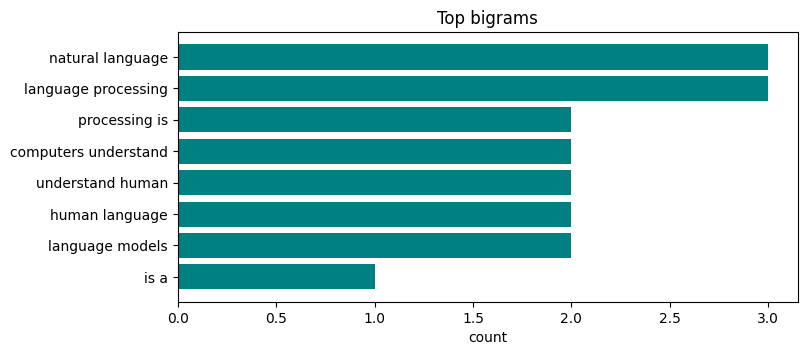

In [6]:
top = bi.most_common(8)
plt.figure(figsize=(8, 3.5))
plt.barh([" ".join(g) for g, _ in top][::-1], [c for _, c in top][::-1], color="teal")
plt.title("Top bigrams"); plt.xlabel("count"); plt.show()